Goals 

- Project NC cells into C cell latent space (scArches)
- Label transfer of new clustering to NC cells
- Label transfer of ABC/HypoMap v1 labels
- Create common UMAP

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
from pathlib import Path
import warnings
import os 

import numpy as np
import pandas as pd
import scanpy as sc
import anndata as ad
import scvi
import matplotlib.pyplot as plt
from dotenv import dotenv_values

from hm3d_utils.manifold import project_to_ref_umap
from hm3d_utils.clustering import project_query

warnings.simplefilter(action='ignore', category=FutureWarning)
sc.set_figure_params(frameon=False, figsize=(10,10), transparent=True)
scvi.settings.seed = 12345

Seed set to 12345


In [3]:
CONFIG = dotenv_values("config.env") 
DATADIR = Path(CONFIG['DATADIR'])

REF_MODELDIR = DATADIR / "5_clustering" / 'all_control_posthoc_qc' 
REF_SCVI_DIR = REF_MODELDIR / "models" / "scvi"

OUTDIR = DATADIR / "6_NC_projection" 
MODEL_OUT_DIR = OUTDIR / "all_integrated"
os.makedirs(MODEL_OUT_DIR, exist_ok=True)

QUERY_FILE = OUTDIR / 'non_control.h5ad'
REF_FILE = REF_MODELDIR / "datasets" / 'control_clustered.h5ad'

OUTFILE_FP = MODEL_OUT_DIR / "HypoMap3D_projected.h5ad"

# Notebook constants
WNN_K = 50
USE_GPU = True

# Let's load the adatas

In [4]:
ref_adata = sc.read_h5ad(REF_FILE) 

query_adata = sc.read_h5ad(QUERY_FILE)

keep a query copy with all genes

In [5]:
query_all_genes = query_adata.copy()

In [6]:
query_adata

AnnData object with n_obs × n_vars = 667177 × 56939
    obs: 'CellID', 'Dataset', 'Sample', 'total_counts', 'n_genes', 'pct_mito', 'Author', 'Source', 'Data_source_link', 'GEO', 'Publication_Link', 'Suspension', 'Technology', 'Author_Sex_harmonized', 'Strain', 'Diet', 'Treatment', 'Age', 'Mean_age_in_weeks', 'IsControl', 'cluster_id_label', 'supertype_id_label', 'subclass_id_label', 'class_id_label', 'C66_named', 'C185_named', 'C286_named', 'C465_named', 'ABC_class_propagated', 'ABC_class_confidence', 'to_be_removed'
    var: 'gene_ids', 'IsMouseTF', 'IsHumanTFOrtholog', 'IsSourceGene', 'IsTargetGene', 'IsHvgExcludedGene', 'IsAnnotationExcludedGene', 'IsPriorityGene', 'IsTopGene'
    uns: 'neighbors', 'tsne', 'umap'
    obsm: 'X_embed', 'X_tsne', 'X_umap'
    obsp: 'connectivities', 'distances'

# scArches NC into C 

In [7]:
# prepare query adata
query_adata = scvi.model.SCVI.prepare_query_anndata(query_adata, str(REF_SCVI_DIR), inplace = False)

INFO     File                                                                                                      
         /REDACTED-path/HypoMap3D-data/v0.9/5_clustering/all_control_posthoc_qc/models/scvi/model.pt  
         already downloaded                                                                                        
INFO     Found 100.0% reference vars in query data.                                                                


In [8]:
# create the new query model instance.
vae_query = scvi.model.SCVI.load_query_data(
    query_adata,
    str(REF_SCVI_DIR)
)

# train
vae_query.train(max_epochs=20, plan_kwargs=dict(weight_decay=0.0))

INFO     File                                                                                                      
         /REDACTED-path/HypoMap3D-data/v0.9/5_clustering/all_control_posthoc_qc/models/scvi/model.pt  
         already downloaded                                                                                        


GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
You are using a CUDA device ('NVIDIA A40') that has Tensor Cores. To properly utilize them, you should set `torch.set_float32_matmul_precision('medium' | 'high')` which will trade-off precision for performance. For more details, read https://pytorch.org/docs/stable/generated/torch.set_float32_matmul_precision.html#torch.set_float32_matmul_precision
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]
/REDACTED-path/HypoMap3D/.venv/lib/python3.11/site-packages/lightning/pytorch/trainer/connectors/data_connector.py:434: The 'train_dataloader' does not have many workers which may be a bottleneck. Consider increasing the value of the `num_workers` argument` to `num_workers=63` in the `DataLoader`

Training:   0%|          | 0/20 [00:00<?, ?it/s]

`Trainer.fit` stopped: `max_epochs=20` reached.


In [9]:
vae_query.save(MODEL_OUT_DIR, overwrite=True)

In [10]:
# get latent representation into query adata
query_adata.obsm["X_embed"] = vae_query.get_latent_representation()

# Let's transfer some labels

## HypoMap3D labels

This is performed in a hierarchy-aware manner where the most probable path along the clustering tree is chosen 

In [11]:
pathmat, P_path = project_query(
    ref_adata,
    query_adata,
    path_keys=[f'L{i}' for i in range(1,6)],
    k=WNN_K,
    use_rep='X_embed',
    use_gpu=USE_GPU
)

2026-06-11 12:48:30 | [WARNING] 
            Precomputed reference neighbor adjacencies, `.obsp['50nn_adjacencies']`, not found. 
            Computing reference 50 neighbors and adding to `.obsp['50nn_adjacencies']`.
            


In [12]:
best_indices = P_path.argmax(axis=1).A1 # best path in the clustering tree

# add best matching label for all levels
for i in range(1,6):
    # pathmat has shape (n_possible_paths, n_levels), i-1 is the idx of the level to be extracted
    query_adata.obs[f"L{i}"] = pathmat[:, i-1][best_indices] 

## Labels from other atlases

To propagate labels available from the other atlases, we need to separate the reference control object into control cells with labels (= new reference) and cells missing those labels first.

Then, we can propagate labels for control cells missing those labels as well as NC cells.

### Hypomap v1

Let's first process the reference (ctrl) data.

In [13]:
hmv1_cols = ['C66_named', 'C185_named', 'C286_named', 'C465_named']

# all cells having C66_named annotation also have annotations for the other resolutions
assert all([all(ref_adata.obs[c].isna().values == ref_adata.obs[hmv1_cols[0]].isna().values) for c in hmv1_cols[1:]])

In [14]:
hmv1_available_mask = ~ref_adata.obs.C66_named.isna()

hmv1_ctrl_ref = ref_adata[hmv1_available_mask]
hmv1_ctrl_query = ref_adata[~hmv1_available_mask]

In [15]:
pathmat, P_path = project_query(
    hmv1_ctrl_ref,
    hmv1_ctrl_query,
    path_keys=hmv1_cols,
    k=WNN_K,
    use_rep='X_embed',
    use_gpu=USE_GPU
)

In [16]:
best_indices = P_path.argmax(axis=1).A1 # best path in the clustering tree

# add best matching label for all resolutions
for i, col in enumerate(hmv1_cols):

    # init column _propagated with known values
    ref_adata.obs[f"{col}_propagated"] = ref_adata.obs[col].copy()
    # add propagated 
    ref_adata.obs.loc[~hmv1_available_mask, f"{col}_propagated"] = pathmat[:, i][best_indices] 

Now, onto the NC data.

In [17]:
pathmat, P_path = project_query(
    hmv1_ctrl_ref,
    query_adata, # NC data
    path_keys=hmv1_cols,
    k=WNN_K,
    use_rep='X_embed',
    use_gpu=USE_GPU
)

best_indices = P_path.argmax(axis=1).A1 # best path in the clustering tree

# add best matching label for all resolutions
for i, col in enumerate(hmv1_cols):
    query_adata.obs[f"{col}_propagated"] = pathmat[:, i][best_indices] 

### ABC

Let's first process the reference (ctrl) data.

In [18]:
abc_cols = ['class_id_label', "subclass_id_label", 'supertype_id_label', 'cluster_id_label',]

# all cells having class_id_label annotation also have annotations for the other resolutions
assert all([all(ref_adata.obs[c].isna().values == ref_adata.obs[abc_cols[0]].isna().values) for c in abc_cols[1:]])

In [19]:
abc_available_mask = ~ref_adata.obs.class_id_label.isna()

abc_ctrl_ref = ref_adata[abc_available_mask]
abc_ctrl_query = ref_adata[~abc_available_mask]

In [20]:
pathmat, P_path = project_query(
    abc_ctrl_ref,
    abc_ctrl_query,
    path_keys=abc_cols,
    k=WNN_K,
    use_rep='X_embed',
    use_gpu=USE_GPU
)

In [21]:
best_indices = P_path.argmax(axis=1).A1 # best path in the clustering tree

# add best matching label for all resolutions
for i, col in enumerate(abc_cols):

    # init column _propagated with known values
    ref_adata.obs[f"{col}_propagated"] = ref_adata.obs[col].copy()
    # add propagated 
    ref_adata.obs.loc[~abc_available_mask, f"{col}_propagated"] = pathmat[:, i][best_indices] 

Now, onto the NC data.

In [22]:
pathmat, P_path = project_query(
    abc_ctrl_ref,
    query_adata, # NC data
    path_keys=abc_cols,
    k=WNN_K,
    use_rep='X_embed',
    use_gpu=USE_GPU
)

best_indices = P_path.argmax(axis=1).A1 # best path in the clustering tree

# add best matching label for all resolutions
for i, col in enumerate(abc_cols):
    query_adata.obs[f"{col}_propagated"] = pathmat[:, i][best_indices] 

# Let's create a common UMAP

In [23]:
sc.tl.umap(ref_adata, min_dist=0.5, spread=1, random_state=69)

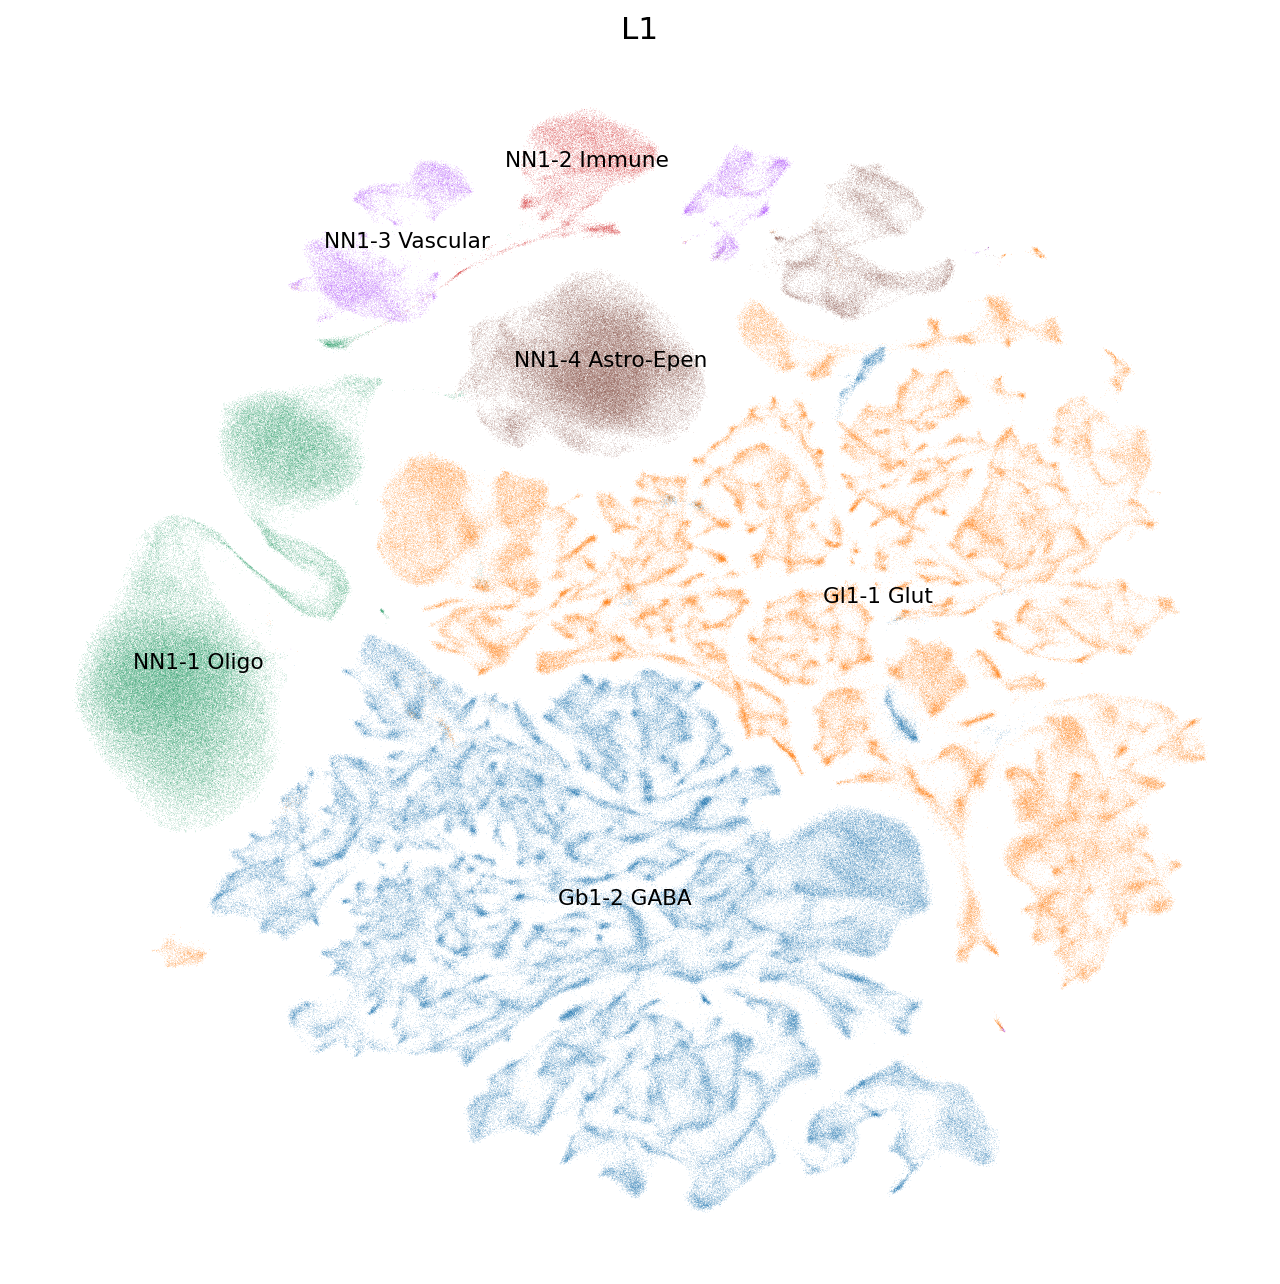

In [24]:
sc.pl.umap(ref_adata, color="L1", legend_loc="on data", legend_fontweight="light", legend_fontsize="x-small")

### Now project NC into C

In [25]:
ref_X_embed = ref_adata.obsm['X_embed']
qry_X_embed = query_adata.obsm['X_embed']

ref_X_umap = ref_adata.obsm['X_umap']

In [26]:
query_adata.obsm['X_umap'], _ = project_to_ref_umap(
    ref_X_embed,
    qry_X_embed,
    ref_X_umap,
    spread=1.0,
    min_dist=0.5,
    verbose=True,
    use_gpu=True,
    n_epochs=100,
    seed=0
)

  0%|          | 0/100 [00:00<?, ?it/s]

	completed  0  /  100 epochs
	completed  10  /  100 epochs
	completed  20  /  100 epochs
	completed  30  /  100 epochs
	completed  40  /  100 epochs
	completed  50  /  100 epochs
	completed  60  /  100 epochs
	completed  70  /  100 epochs
	completed  80  /  100 epochs
	completed  90  /  100 epochs


In [27]:
query_all_genes.obs = query_adata.obs.copy()
query_all_genes.uns = query_adata.uns.copy()
query_all_genes.obsm = query_adata.obsm.copy()
query_all_genes.obsp = query_adata.obsp.copy()

concat_adata = sc.concat([ref_adata, query_all_genes], join="outer", )

concat_adata

AnnData object with n_obs × n_vars = 1565227 × 56939
    obs: 'CellID', 'Dataset', 'Sample', 'total_counts', 'n_genes', 'pct_mito', 'Author', 'Source', 'Data_source_link', 'GEO', 'Publication_Link', 'Suspension', 'Technology', 'Author_Sex_harmonized', 'Strain', 'Diet', 'Treatment', 'Age', 'Mean_age_in_weeks', 'IsControl', 'cluster_id_label', 'supertype_id_label', 'subclass_id_label', 'class_id_label', 'C66_named', 'C185_named', 'C286_named', 'C465_named', 'ABC_class_propagated', 'ABC_class_confidence', 'to_be_removed', 'IsNeuronal', 'major_features', 'major_features_propagated', 'major_features_confidence', 'ABC_supertype_propagated', 'ABC_supertype_confidence', 'ABC_subclass_propagated', 'ABC_subclass_confidence', 'ABC_cluster_propagated', 'ABC_cluster_confidence', 'L1', 'L2', 'L3', 'L4', 'L5', 'C66_named_propagated', 'C185_named_propagated', 'C286_named_propagated', 'C465_named_propagated', 'class_id_label_propagated', 'subclass_id_label_propagated', 'supertype_id_label_propagated', 

... storing 'L1' as categorical
... storing 'L2' as categorical
... storing 'L3' as categorical
... storing 'L4' as categorical
... storing 'L5' as categorical
... storing 'C66_named_propagated' as categorical
... storing 'C185_named_propagated' as categorical
... storing 'C286_named_propagated' as categorical
... storing 'C465_named_propagated' as categorical
... storing 'class_id_label_propagated' as categorical
... storing 'subclass_id_label_propagated' as categorical
... storing 'supertype_id_label_propagated' as categorical
... storing 'cluster_id_label_propagated' as categorical


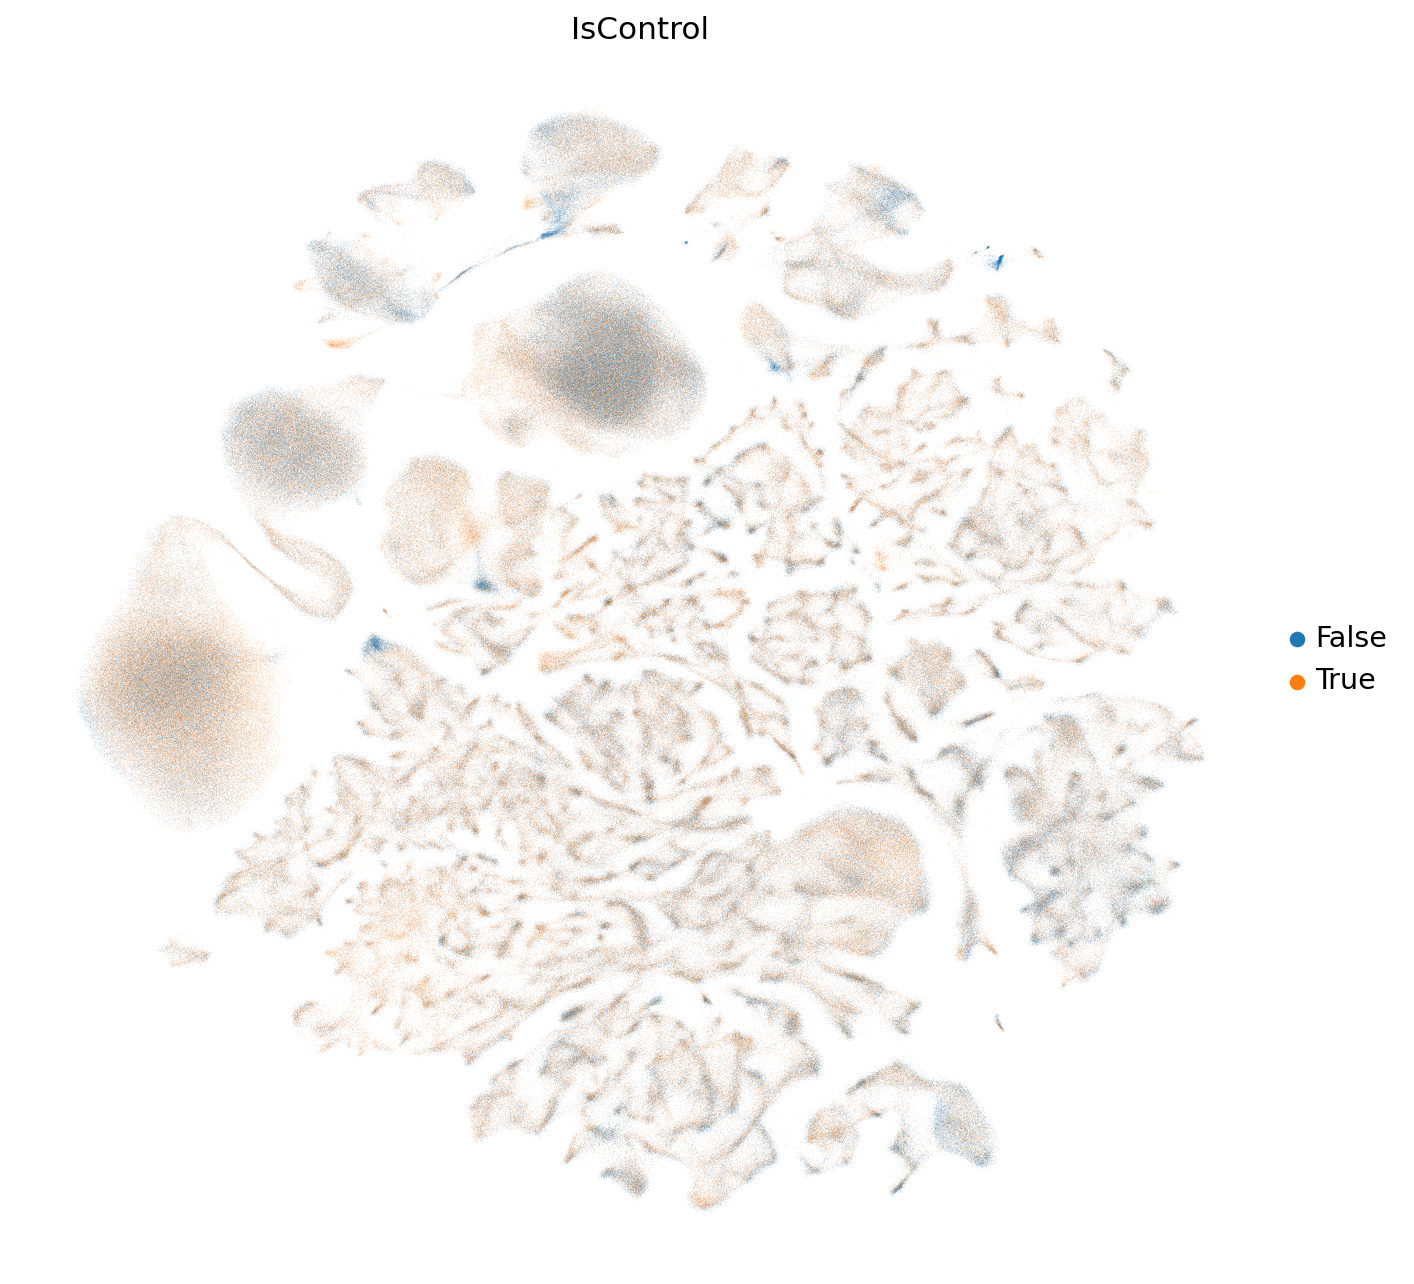

In [28]:
sc.pl.umap(concat_adata, color="IsControl", )

# Let's tidy up the adata and save it

In [29]:
cols_to_drop = (
    concat_adata.obs.columns[
        concat_adata.obs.columns.str.contains(
            r"ABC|_scvi|major_features"
        )
    ]
    .tolist()
)

cols_to_drop += ["to_be_removed", "IsNeuronal"]

In [30]:
concat_adata.obs.drop(columns=cols_to_drop, inplace=True)
del concat_adata.uns, concat_adata.obsm["X_tsne"]

In [34]:
# add back var
concat_adata.var = ref_adata.var.loc[concat_adata.var.index, :].copy()

In [35]:
concat_adata

AnnData object with n_obs × n_vars = 1565227 × 56939
    obs: 'CellID', 'Dataset', 'Sample', 'total_counts', 'n_genes', 'pct_mito', 'Author', 'Source', 'Data_source_link', 'GEO', 'Publication_Link', 'Suspension', 'Technology', 'Author_Sex_harmonized', 'Strain', 'Diet', 'Treatment', 'Age', 'Mean_age_in_weeks', 'IsControl', 'cluster_id_label', 'supertype_id_label', 'subclass_id_label', 'class_id_label', 'C66_named', 'C185_named', 'C286_named', 'C465_named', 'L1', 'L2', 'L3', 'L4', 'L5', 'C66_named_propagated', 'C185_named_propagated', 'C286_named_propagated', 'C465_named_propagated', 'class_id_label_propagated', 'subclass_id_label_propagated', 'supertype_id_label_propagated', 'cluster_id_label_propagated'
    var: 'gene_ids', 'IsMouseTF', 'IsHumanTFOrtholog', 'IsSourceGene', 'IsTargetGene', 'IsHvgExcludedGene', 'IsAnnotationExcludedGene', 'IsPriorityGene', 'IsTopGene', 'IsHvg'
    obsm: 'X_embed', 'X_umap'

In [36]:
concat_adata.write_h5ad(OUTFILE_FP)